# Predictive Analytics Using Historical Customer Data

## Objective
Predict customer profit using historical customer behavior,
purchase frequency, revenue, quantity, discount, and other features.

## Model
Regression

## Target Variable
Total_Profit

In [ ]:
import os

os.listdir("/content")

['.config', 'sample_data']

In [ ]:
import pandas as pd

df = pd.read_excel(
    "/content/sample_data/Customer_Segmentation_Predictive_Analytics.xlsx"
)

df.head()

,Customer ID,Customer_Name,Age,Gender,Income_Group,Occupation,Customer_Type,Region,City,Last_Purchase_Date,...,Average_Discount,Categories_Purchased,Products_Purchased,Recency,Average_Order_Value,Profit_Margin,Cluster,Profit_Per_Order,Revenue_Per_Order,High_Profit_Customer
0,CUST-1001,Arjun Verma,35,Male,Lower-Middle,IT Professional,Individual,North,Dehradun,2026-02-23,...,0.075000,3,6,158,23158.311667,0.110741,1,2564.563333,23158.311667,0
1,CUST-1002,Arjun Patel,31,Male,Middle,Student,Individual,North,Dehradun,2026-07-15,...,0.117143,3,6,16,91991.128571,0.115484,0,10623.472857,91991.128571,1
2,CUST-1003,Sneha Gupta,55,Female,Upper-Middle,Student,Business,West,Pune,2026-06-15,...,0.058571,3,6,46,38524.707143,0.130797,1,5038.922857,38524.707143,1
3,CUST-1004,Karthik Rao,39,Male,Low,IT Professional,Business,South,Hyderabad,2026-02-17,...,0.030000,3,4,164,103270.757500,0.129199,0,13342.480000,103270.757500,1
4,CUST-1005,Manish Mehta,25,Female,Low,Healthcare Professional,Business,North,Dehradun,2026-06-29,...,0.128333,4,6,32,115894.926667,0.180620,0,20932.935000,115894.926667,1


## Import Required Libraries

In this step, we import the Python libraries required for data analysis, visualization, preprocessing, machine learning, and model evaluation.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## Locate the Dataset

Before loading the dataset, we check the Colab storage to find the exact location of the uploaded Excel file.

This prevents FileNotFoundError caused by using an incorrect file path.

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".xlsx"):
            print(os.path.join(root, file))

/content/sample_data/Customer_Segmentation_Predictive_Analytics.xlsx


## Understand the Dataset Structure

This step examines the size and structure of the dataset.

We check the number of rows and columns and inspect the data types of each column.

This helps us understand what type of data is available before starting preprocessing.

In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

df.info()

Number of Rows: 1194
Number of Columns: 24
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1194 entries, 0 to 1193
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer ID           1194 non-null   object        
 1   Customer_Name         1194 non-null   object        
 2   Age                   1194 non-null   int64         
 3   Gender                1194 non-null   object        
 4   Income_Group          1194 non-null   object        
 5   Occupation            1194 non-null   object        
 6   Customer_Type         1194 non-null   object        
 7   Region                1194 non-null   object        
 8   City                  1194 non-null   object        
 9   Last_Purchase_Date    1194 non-null   datetime64[ns]
 10  Frequency             1194 non-null   int64         
 11  Monetary              1194 non-null   float64       
 12  Total_Quantity        1194 non-nu

## Check Missing Values

Missing values can negatively affect machine learning models.

In this step, we identify the number of missing values in each column so that they can be handled during data preprocessing.

In [ ]:
print(df.isnull().sum())

print(
    "\nTotal Missing Values:",
    df.isnull().sum().sum()
)

Customer ID             0
Customer_Name           0
Age                     0
Gender                  0
Income_Group            0
Occupation              0
Customer_Type           0
Region                  0
City                    0
Last_Purchase_Date      0
Frequency               0
Monetary                0
Total_Quantity          0
Total_Profit            0
Average_Discount        0
Categories_Purchased    0
Products_Purchased      0
Recency                 0
Average_Order_Value     0
Profit_Margin           0
Cluster                 0
Profit_Per_Order        0
Revenue_Per_Order       0
High_Profit_Customer    0
dtype: int64

Total Missing Values: 0


## Check Duplicate Records

Duplicate records can cause the same customer information to be considered multiple times.

In this step, we identify duplicate rows and remove them if they exist.

In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


## Remove Duplicate Records

If duplicate rows are present, they are removed to improve the quality and reliability of the dataset.

In [ ]:
df = df.drop_duplicates()

print("Rows After Removing Duplicates:", len(df))

Rows After Removing Duplicates: 1194


## Analyze the Target Variable

The target variable is the value that our machine learning model will predict.

For this project, Total_Profit is selected as the target variable.

We examine its statistical distribution to understand the range and variation of customer profit.

In [ ]:
df["Total_Profit"].describe()

,Total_Profit
count,1194.000000
mean,30488.613836
std,23962.363018
min,51.230000
25%,13058.682500
50%,25040.895000
75%,42901.962500
max,153249.830000


## Define Features and Target Variable

In supervised machine learning, the input variables are called features (X), while the value we want to predict is called the target variable (y).

For this project:

- X = Customer and purchasing features
- y = Total_Profit

Columns that directly contain or are derived from Total_Profit are excluded to prevent data leakage.

In [ ]:
remove_columns = [
    "Total_Profit",
    "Profit_Per_Order",
    "High_Profit_Customer",
    "Cluster"
]

X = df.drop(
    columns=[col for col in remove_columns if col in df.columns]
)

y = df["Total_Profit"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (1194, 20)
Target Shape: (1194,)


## Remove Identification Columns

Customer ID, customer name, and last purchase date are not directly required as predictive features for this regression model.

These columns are removed to reduce unnecessary information and avoid using customer identifiers as model inputs.

In [ ]:
remove_columns = [
    "Customer ID",
    "Customer_Name",
    "Last_Purchase_Date"
]

X = X.drop(
    columns=[col for col in remove_columns if col in X.columns]
)

print("Remaining Features:")
print(X.columns.tolist())

Remaining Features:
['Age', 'Gender', 'Income_Group', 'Occupation', 'Customer_Type', 'Region', 'City', 'Frequency', 'Monetary', 'Total_Quantity', 'Average_Discount', 'Categories_Purchased', 'Products_Purchased', 'Recency', 'Average_Order_Value', 'Profit_Margin', 'Revenue_Per_Order']


## Identify Numerical and Categorical Features

Machine learning models require numerical input.

Numerical columns can be used directly after handling missing values, while categorical columns such as gender, occupation, and region need to be converted into numerical representations.

This step separates both types of features.

In [ ]:
numeric_columns = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns

categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns

print("Numerical Columns:")
print(list(numeric_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['Age', 'Frequency', 'Monetary', 'Total_Quantity', 'Average_Discount', 'Categories_Purchased', 'Products_Purchased', 'Recency', 'Average_Order_Value', 'Profit_Margin', 'Revenue_Per_Order']

Categorical Columns:
['Gender', 'Income_Group', 'Occupation', 'Customer_Type', 'Region', 'City']


## Data Preprocessing

Data preprocessing prepares the dataset for machine learning.

For numerical features, missing values are replaced using the median.

For categorical features, missing values are replaced using the most frequent value and categorical variables are converted into numerical values using one-hot encoding.

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

## Split the Dataset into Training and Testing Sets

The dataset is divided into two parts.

80% of the data is used for training the machine learning models, while 20% is used for testing their performance on unseen data.

A random state is used to make the results reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

Training Rows: 955
Testing Rows: 239


## Build Linear Regression Model

Linear Regression is used as the first predictive model.

It attempts to identify a linear relationship between customer characteristics and total profit.

This model provides a baseline that can later be compared with a more advanced Random Forest Regression model.

In [ ]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


## Generate Linear Regression Predictions

After training the Linear Regression model, we use the testing data to predict customer profit.

These predicted values will later be compared with the actual profit values.

In [ ]:
y_pred_linear = linear_model.predict(X_test)

print("First 10 Predicted Values:")
print(y_pred_linear[:10])

First 10 Predicted Values:
[59833.4701725  15946.18435878 26390.96967911 22137.30915899
 15245.11740015 46785.11627195 50537.27053655  8740.18102648
 39617.93575548 60359.21902388]


## Evaluate Linear Regression Model

The Linear Regression model is evaluated using MAE, MSE, RMSE, and R² score.

These metrics help measure how accurately the model predicts customer profit.

Lower MAE and RMSE indicate smaller prediction errors, while a higher R² score indicates better explanatory performance.

In [ ]:
mae = mean_absolute_error(y_test, y_pred_linear)
mse = mean_squared_error(y_test, y_pred_linear)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

Linear Regression Results
-------------------------
MAE : 3404.129494080991
MSE : 23564990.00057843
RMSE: 4854.378436069692
R² Score: 0.9544050915077968


## Build Random Forest Regression Model

Random Forest Regression is used as a second predictive model.

Random Forest can capture more complex and non-linear relationships between customer behavior and profit.

Its performance will be compared with Linear Regression to identify the better-performing model.

In [ ]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=10
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## Generate Random Forest Predictions

The trained Random Forest model is used to predict customer profit for the unseen testing dataset.

In [ ]:
y_pred_rf = random_forest_model.predict(X_test)

print("First 10 Predicted Values:")
print(y_pred_rf[:10])

First 10 Predicted Values:
[66498.49049468 17483.28952111 26630.77858089 22790.03861375
 18228.21226863 50332.66616144 46464.0100196   5045.31486104
 39645.73202311 61071.89075518]


## Evaluate Random Forest Model

The Random Forest model is evaluated using the same metrics as Linear Regression.

Using the same evaluation metrics allows us to make a fair comparison between the two models.

In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R² Score:", r2_rf)

Random Forest Results
---------------------
MAE : 776.9476147251044
MSE : 2859877.829602279
RMSE: 1691.1173317077319
R² Score: 0.9944665426152782


## Compare Predictive Models

The performance of Linear Regression and Random Forest Regression is compared using MAE, RMSE, and R² score.

The model with lower prediction errors and higher R² score will be selected as the preferred predictive model.

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        mae_rf
    ],
    "RMSE": [
        rmse,
        rmse_rf
    ],
    "R2_Score": [
        r2,
        r2_rf
    ]
})

model_comparison

,Model,MAE,RMSE,R2_Score
0,Linear Regression,3404.129494,4854.378436,0.954405
1,Random Forest,776.947615,1691.117332,0.994467


## Create Actual vs Predicted Results

The actual profit values from the testing dataset are compared with the predicted values generated by the selected model.

This table helps identify how closely the model predictions match the actual customer profit.

In [ ]:
results = pd.DataFrame({
    "Actual_Profit": y_test.values,
    "Predicted_Profit": y_pred_rf
})

results["Prediction_Error"] = (
    results["Actual_Profit"] -
    results["Predicted_Profit"]
)

results.head(10)

,Actual_Profit,Predicted_Profit,Prediction_Error
0,68806.02,66498.490495,2307.529505
1,16852.80,17483.289521,-630.489521
2,26320.34,26630.778581,-310.438581
3,22613.45,22790.038614,-176.588614
4,17444.26,18228.212269,-783.952269
5,51706.59,50332.666161,1373.923839
6,45969.91,46464.010020,-494.100020
7,4998.71,5045.314861,-46.604861
8,38368.43,39645.732023,-1277.302023
9,62828.85,61071.890755,1756.959245


## Visualize Actual vs Predicted Profit

A scatter plot is created to compare actual customer profit with predicted customer profit.

Points closer to the ideal diagonal relationship indicate more accurate predictions.

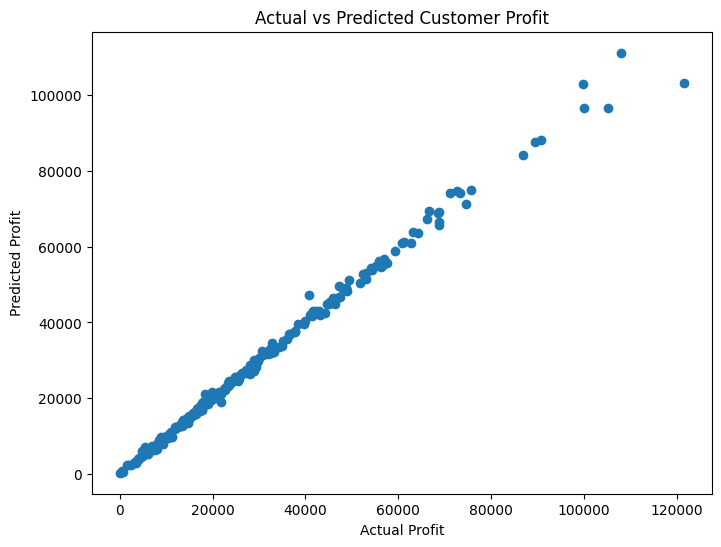

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    results["Actual_Profit"],
    results["Predicted_Profit"]
)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Predicted Customer Profit")

plt.show()

## Compare Actual and Predicted Profit

The first 20 test observations are visualized using a line chart.

This allows us to visually compare the actual customer profit with the profit predicted by the model.

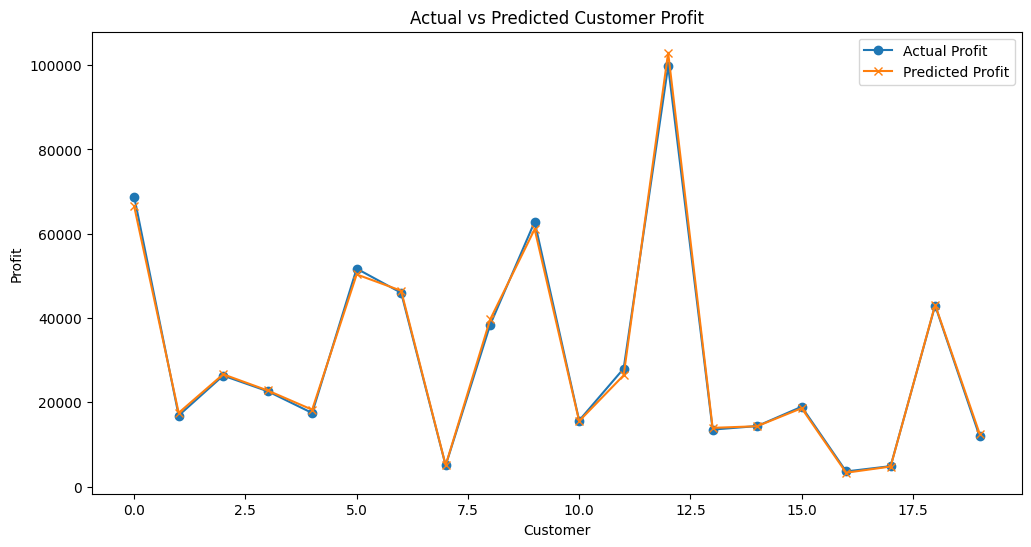

In [ ]:
comparison = results.head(20)

plt.figure(figsize=(12, 6))

plt.plot(
    comparison["Actual_Profit"].values,
    marker="o",
    label="Actual Profit"
)

plt.plot(
    comparison["Predicted_Profit"].values,
    marker="x",
    label="Predicted Profit"
)

plt.xlabel("Customer")
plt.ylabel("Profit")
plt.title("Actual vs Predicted Customer Profit")

plt.legend()

plt.show()

## Identify Important Predictive Features

Random Forest provides feature importance values that show which customer characteristics contributed most to the prediction.

This helps us understand the factors that are most influential in predicting customer profit.

In [ ]:
rf_model = random_forest_model.named_steps["model"]

feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance
2,numeric__Monetary,0.893749
9,numeric__Profit_Margin,0.097315
4,numeric__Average_Discount,0.000947
0,numeric__Age,0.000871
8,numeric__Average_Order_Value,0.000855
10,numeric__Revenue_Per_Order,0.000724
7,numeric__Recency,0.000668
3,numeric__Total_Quantity,0.000625
6,numeric__Products_Purchased,0.000282
1,numeric__Frequency,0.000245


## Visualize Top Predictive Features

The top 10 most important features are visualized using a horizontal bar chart.

This provides an easy-to-understand view of which variables have the greatest influence on the Random Forest prediction.

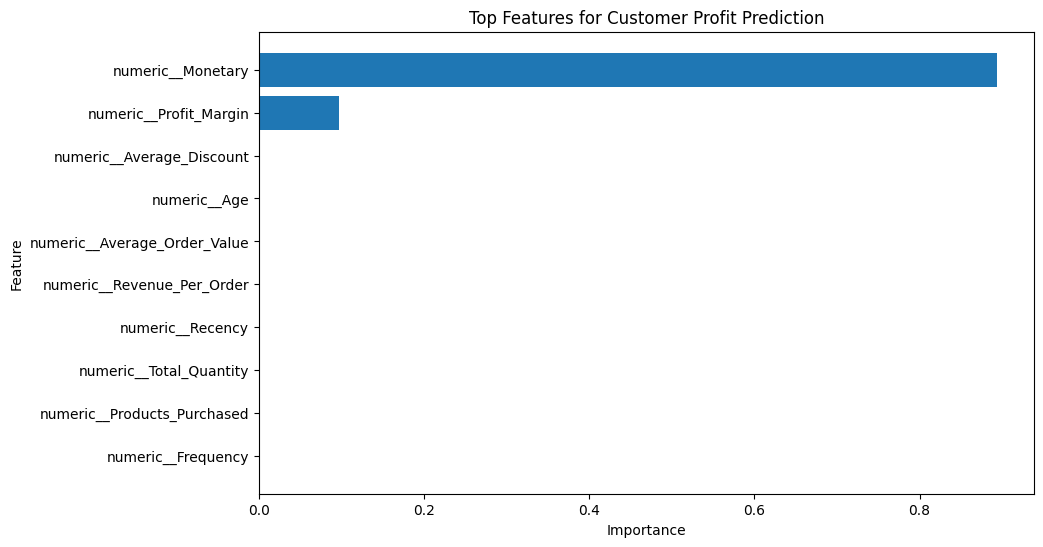

In [ ]:
top_features = importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features for Customer Profit Prediction")

plt.show()

## Export Prediction Results

The final prediction results, model comparison metrics, and feature importance values are saved as Excel files.

These files can be used later for reporting, portfolio documentation, and Power BI visualization.

In [ ]:
results.to_excel(
    "Customer_Profit_Predictions.xlsx",
    index=False
)

model_comparison.to_excel(
    "Model_Comparison.xlsx",
    index=False
)

importance.to_excel(
    "Profit_Feature_Importance.xlsx",
    index=False
)

print("All result files saved successfully.")

All result files saved successfully.


# Predictive Analytics Using Historical Customer Data

## Import Required Libraries
[Code]

## Locate the Dataset
[Code]

## Load the Dataset
[Code]

## Understand the Dataset Structure
[Code]

## Display Dataset Columns
[Code]

## Check Missing Values
[Code]

## Check Duplicate Records
[Code]

## Analyze the Target Variable
[Code]

## Define Features and Target Variable
[Code]

## Remove Identification Columns
[Code]

## Identify Numerical and Categorical Features
[Code]

## Data Preprocessing
[Code]

## Split the Dataset
[Code]

## Build Linear Regression Model
[Code]

## Generate Predictions
[Code]

## Evaluate Model
[Code]

## Build Random Forest Model
[Code]

## Evaluate Random Forest
[Code]

## Compare Models
[Code]

## Create Actual vs Predicted Results
[Code]

## Visualize Predictions
[Code]

## Identify Important Features
[Code]

## Export Results
[Code]

In [ ]:
# Export the cleaned dataset to Excel

cleaned_file = "Customer_Segmentation_Cleaned.xlsx"

df.to_excel(
    cleaned_file,
    index=False
)

print("Cleaned dataset exported successfully.")
print("File name:", cleaned_file)

Cleaned dataset exported successfully.
File name: Customer_Segmentation_Cleaned.xlsx


In [ ]:
from google.colab import files

files.download("Customer_Segmentation_Cleaned.xlsx")


FileNotFoundError: Cannot find file: Customer_Segmentation_Cleaned.xlsx

In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving Customer_Segmentation_Cleaned.xlsx to Customer_Segmentation_Cleaned.xlsx


In [ ]:
file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

df.head()

,Customer ID,Customer_Name,Age,Gender,Income_Group,Occupation,Customer_Type,Region,City,Last_Purchase_Date,...,Average_Discount,Categories_Purchased,Products_Purchased,Recency,Average_Order_Value,Profit_Margin,Cluster,Profit_Per_Order,Revenue_Per_Order,High_Profit_Customer
0,CUST-1001,Arjun Verma,35,Male,Lower-Middle,IT Professional,Individual,North,Dehradun,2026-02-23,...,0.075000,3,6,158,23158.311667,0.110741,1,2564.563333,23158.311667,0
1,CUST-1002,Arjun Patel,31,Male,Middle,Student,Individual,North,Dehradun,2026-07-15,...,0.117143,3,6,16,91991.128571,0.115484,0,10623.472857,91991.128571,1
2,CUST-1003,Sneha Gupta,55,Female,Upper-Middle,Student,Business,West,Pune,2026-06-15,...,0.058571,3,6,46,38524.707143,0.130797,1,5038.922857,38524.707143,1
3,CUST-1004,Karthik Rao,39,Male,Low,IT Professional,Business,South,Hyderabad,2026-02-17,...,0.030000,3,4,164,103270.757500,0.129199,0,13342.480000,103270.757500,1
4,CUST-1005,Manish Mehta,25,Female,Low,Healthcare Professional,Business,North,Dehradun,2026-06-29,...,0.128333,4,6,32,115894.926667,0.180620,0,20932.935000,115894.926667,1


In [ ]:
df.columns.tolist()

['Customer ID',
 'Customer_Name',
 'Age',
 'Gender',
 'Income_Group',
 'Occupation',
 'Customer_Type',
 'Region',
 'City',
 'Last_Purchase_Date',
 'Frequency',
 'Monetary',
 'Total_Quantity',
 'Total_Profit',
 'Average_Discount',
 'Categories_Purchased',
 'Products_Purchased',
 'Recency',
 'Average_Order_Value',
 'Profit_Margin',
 'Cluster',
 'Profit_Per_Order',
 'Revenue_Per_Order',
 'High_Profit_Customer']

In [ ]:
import pandas as pd

# Make sure the date column is a proper date
df['Last_Purchase_Date'] = pd.to_datetime(df['Last_Purchase_Date'])

# Create monthly revenue
monthly_revenue = (
    df.groupby(df['Last_Purchase_Date'].dt.to_period('M'))['Revenue_Per_Order']
      .sum()
      .reset_index()
)

# Convert month back to a normal date
monthly_revenue['Last_Purchase_Date'] = (
    monthly_revenue['Last_Purchase_Date'].dt.to_timestamp()
)

monthly_revenue.columns = ['Date', 'Revenue']

monthly_revenue

,Date,Revenue
0,2024-03-01,3.307672e+04
1,2024-06-01,1.238657e+05
2,2024-07-01,1.039617e+05
3,2024-09-01,3.153515e+04
4,2024-10-01,4.120429e+04
5,2024-11-01,1.950847e+05
6,2024-12-01,2.164916e+05
7,2025-01-01,1.805359e+05
8,2025-02-01,2.506382e+05
9,2025-03-01,3.118974e+05


In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Create a numeric time variable
monthly_revenue['Month_Number'] = np.arange(len(monthly_revenue))

# Prepare data
X = monthly_revenue[['Month_Number']]
y = monthly_revenue['Revenue']

# Create and train the model
model = LinearRegression()
model.fit(X, y)

# Predict the historical values
monthly_revenue['Predicted_Revenue'] = model.predict(X)

# Show the result
monthly_revenue[['Date', 'Revenue', 'Predicted_Revenue']].tail()

,Date,Revenue,Predicted_Revenue
21,2026-03-01,3.523780e+06,3.497172e+06
22,2026-04-01,4.212598e+06,3.725580e+06
23,2026-05-01,5.029421e+06,3.953989e+06
24,2026-06-01,5.555267e+06,4.182397e+06
25,2026-07-01,7.728544e+06,4.410805e+06


In [ ]:
# Create the next 6 month numbers
future_months = np.arange(
    len(monthly_revenue),
    len(monthly_revenue) + 6
)

# Predict revenue for the next 6 months
future_predictions = model.predict(
    future_months.reshape(-1, 1)
)

# Create future dates
future_dates = pd.date_range(
    start=monthly_revenue['Date'].max() + pd.DateOffset(months=1),
    periods=6,
    freq='MS'
)

# Create forecast table
forecast = pd.DataFrame({
    'Date': future_dates,
    'Revenue': np.nan,
    'Predicted_Revenue': future_predictions
})

forecast

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Date,Revenue,Predicted_Revenue
0,2026-08-01,NaN,4.639213e+06
1,2026-09-01,NaN,4.867621e+06
2,2026-10-01,NaN,5.096030e+06
3,2026-11-01,NaN,5.324438e+06
4,2026-12-01,NaN,5.552846e+06
5,2027-01-01,NaN,5.781254e+06


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import pandas as pd
import numpy as np

df['Last_Purchase_Date'] = pd.to_datetime(df['Last_Purchase_Date'])

monthly_revenue = (
    df.groupby(df['Last_Purchase_Date'].dt.to_period('M'))['Revenue_Per_Order']
      .sum()
      .reset_index()
)

monthly_revenue['Last_Purchase_Date'] = (
    monthly_revenue['Last_Purchase_Date'].dt.to_timestamp()
)

monthly_revenue.columns = ['Date', 'Revenue']

monthly_revenue

,Date,Revenue
0,2024-03-01,3.307672e+04
1,2024-06-01,1.238657e+05
2,2024-07-01,1.039617e+05
3,2024-09-01,3.153515e+04
4,2024-10-01,4.120429e+04
5,2024-11-01,1.950847e+05
6,2024-12-01,2.164916e+05
7,2025-01-01,1.805359e+05
8,2025-02-01,2.506382e+05
9,2025-03-01,3.118974e+05


In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Create month numbers
monthly_revenue['Month_Number'] = np.arange(len(monthly_revenue))

# Input and target
X = monthly_revenue[['Month_Number']]
y = monthly_revenue['Revenue']

# Create and train model
model = LinearRegression()
model.fit(X, y)

# Predict revenue for existing months
monthly_revenue['Predicted_Revenue'] = model.predict(X)

# Show actual vs predicted
monthly_revenue[['Date', 'Revenue', 'Predicted_Revenue']]

,Date,Revenue,Predicted_Revenue
0,2024-03-01,3.307672e+04,-1.299400e+06
1,2024-06-01,1.238657e+05,-1.070992e+06
2,2024-07-01,1.039617e+05,-8.425836e+05
3,2024-09-01,3.153515e+04,-6.141754e+05
4,2024-10-01,4.120429e+04,-3.857672e+05
5,2024-11-01,1.950847e+05,-1.573590e+05
6,2024-12-01,2.164916e+05,7.104916e+04
7,2025-01-01,1.805359e+05,2.994574e+05
8,2025-02-01,2.506382e+05,5.278656e+05
9,2025-03-01,3.118974e+05,7.562738e+05


In [ ]:
# Next 6 months
future_month_numbers = np.arange(
    len(monthly_revenue),
    len(monthly_revenue) + 6
)

# Predict future revenue
future_predictions = model.predict(
    future_month_numbers.reshape(-1, 1)
)

# Create future dates
future_dates = pd.date_range(
    start=monthly_revenue['Date'].max() + pd.DateOffset(months=1),
    periods=6,
    freq='MS'
)

# Create forecast table
future_forecast = pd.DataFrame({
    'Date': future_dates,
    'Forecast_Revenue': future_predictions
})

future_forecast

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Date,Forecast_Revenue
0,2026-08-01,4.639213e+06
1,2026-09-01,4.867621e+06
2,2026-10-01,5.096030e+06
3,2026-11-01,5.324438e+06
4,2026-12-01,5.552846e+06
5,2027-01-01,5.781254e+06


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Actual and predicted historical revenue
actual = monthly_revenue['Revenue']
predicted = monthly_revenue['Predicted_Revenue']

# Calculate accuracy metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

print("Model Accuracy Results")
print("----------------------")
print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"R²   : {r2:.4f}")

Model Accuracy Results
----------------------
MAE  : 871,085.73
RMSE : 1,082,134.73
R²   : 0.7148


In [ ]:
# Save the forecast results as CSV
future_forecast.to_csv(
    'Revenue_Forecast.csv',
    index=False
)

print("Revenue_Forecast.csv created successfully!")

Revenue_Forecast.csv created successfully!


In [ ]:
from google.colab import files

files.download('Revenue_Forecast.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>